# 02 — Non-stationary bids (week 34)

The stream's markups change once, at t* = 240 h after the stream start. Nothing else changes: not H, the costs,
the arrivals, the requests, the durations, the prices or the carbon.

| Scenario | Change at t* |
|---|---|
| none | no change (stationary) |
| S1 bids fall | m → 0.5 m |
| S6 bids spread | σ 0.3 → 0.5, E[m] = 1 |
| S2 bids rise | m → 1.75 m |

Models, in every environment: fluid OPT (hindsight, before and after t*), Practical (C3), Greedy-Pos, No learning
(the practical model frozen at Phase 0), Theoretical, and, when cached, Practical + calibrated tests.

Everything here is read from the caches of `scripts/run_scenarios.py`; nothing is run. The tables come from
`scripts/scenarios_analysis.py`. The write-up is `reports/week34/scenarios_results.md`.

Rebuild: `dlent_venv/bin/python notebooks/src/build.py 02_nonstationary --execute`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
warnings.simplefilter("ignore")
import scenarios_analysis as sa  # noqa: E402
from dlent_rt import scenarios as sc  # noqa: E402

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)
MODELS = sa.models_cached()
# fixed colour per model (Okabe-Ito, colourblind-safe), never by rank
COLOR = dict(fluid="#000000", practical="#0072B2", practical_calibrated="#56B4E9", no_learning="#E69F00",
             greedy_pos="#009E73", theoretical="#CC79A7")
T_STAR = 240.0
print("models cached in every environment:", [sa.LABEL[m] for m in MODELS])

models cached in every environment: ['fluid OPT', 'Greedy-Pos', 'No learning', 'Practical (C3)', 'Theoretical']


## 1. Reward before and after t*

"% OPT after" is the share of fluid OPT's reward after t*. Fluid OPT is the sum of two hindsight LPs, one before
and one after t*: an upper bound, not a policy.

In [2]:
rw = sa.rewards()
rw.replace({"env": sa.ENV_LABEL, "model": sa.LABEL})[
    ["env", "model", "reward", "before t*", "after t*", "% OPT", "% OPT after", "admitted after"]]

,env,model,reward,before t*,after t*,% OPT,% OPT after,admitted after
0,none (stationary),fluid OPT,"3,546.14","1,454.54","2,091.59",100.00,100.00,NaN
1,none (stationary),Greedy-Pos,"2,834.84","1,146.44","1,688.40",79.94,80.72,"92,825.00"
2,none (stationary),No learning,"3,078.90","1,255.73","1,823.16",86.82,87.17,"94,527.00"
3,none (stationary),Practical (C3),"3,104.05","1,271.08","1,832.97",87.53,87.64,"93,353.00"
4,none (stationary),Theoretical,"2,248.04",895.33,"1,352.71",63.39,64.67,"66,790.00"
5,S1 bids fall,fluid OPT,"1,969.04","1,454.54",514.50,100.00,100.00,NaN
6,S1 bids fall,Greedy-Pos,"1,337.32","1,146.44",190.88,67.92,37.10,"14,130.00"
7,S1 bids fall,No learning,"1,403.26","1,255.73",147.53,71.27,28.67,"10,042.00"
8,S1 bids fall,Practical (C3),"1,668.23","1,271.08",397.15,84.72,77.19,"43,826.00"
9,S1 bids fall,Theoretical,"1,204.73",895.33,309.40,61.18,60.14,"35,812.00"


**The value of learning** is Practical against No learning, after t*. **The value of the practical changes** is
Practical against Theoretical.

In [3]:
sa.learning_gain(rw).replace({"env": sa.ENV_LABEL})

,env,"practical / no learning, after t*","practical / theoretical, after t*","no learning, after t*"
0,none (stationary),1.01,1.36,"1,823.16"
1,S1 bids fall,2.69,1.28,147.53
2,S6 bids spread,0.98,1.33,"1,854.35"
3,S2 bids rise,1.19,1.19,"2,915.80"


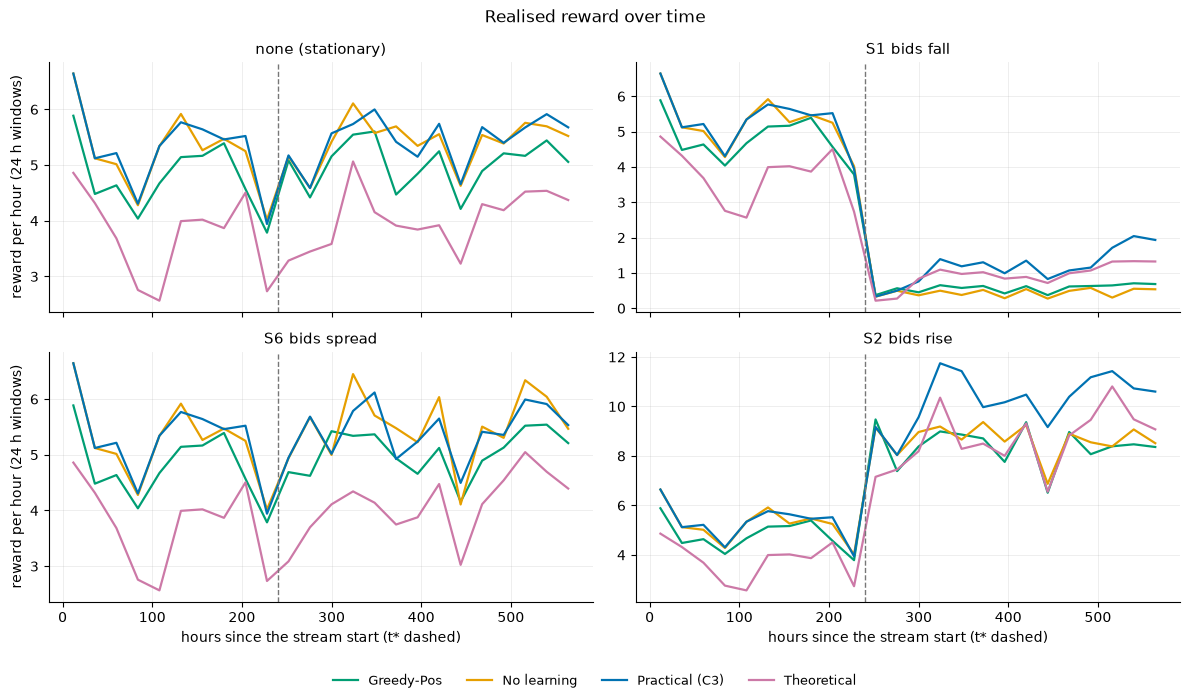

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, e in zip(axes.flat, sa.ENVS):
    for m in [m for m in MODELS if m != "fluid"]:
        d = sa.reward_rate(e, m)
        ax.plot(d.hour, d["reward per h"], color=COLOR[m], lw=1.6, label=sa.LABEL[m])
    ax.axvline(T_STAR, color="#777777", lw=1, ls="--")
    ax.set_title(sa.ENV_LABEL[e], fontsize=11)
    ax.grid(alpha=0.25, lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("hours since the stream start (t* dashed)")
for ax in axes[:, 0]:
    ax.set_ylabel("reward per hour (24 h windows)")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(l), fontsize=9, frameon=False)
fig.suptitle("Realised reward over time", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))

## 2. Detection: how the phases ended

Tests 2 and 3 never fire, with the paper's thresholds (`reports/week34/test_margins.md`): they are out of reach by
2–3 orders of magnitude. Phases end only by Test 1 (capacity) or by timeout. Adaptation therefore comes from that
cadence: the phase that contains t* ends, ReInit refits (μ̂, σ̂) on data that mix the two regimes, and the next
phase refits on post-change data only.

"Adapted phase starts" is the first phase whose μ̂ is within 0.1 of the true post-change μ (S1, S2), or whose σ̂ is
within 0.05 of the true σ (S6).

In [5]:
sa.detection().replace({"env": sa.ENV_LABEL, "model": sa.LABEL})

,env,model,phases,ends,first end after t* (h),by,Test 2/3 delay (h),adapted phase starts (h after t*)
0,none (stationary),Practical (C3),13,"horizon 1, test1 12",3.45,test1,NaN,NaN
1,none (stationary),Theoretical,11,"horizon 1, test1 8, timeout 2",45.24,timeout,NaN,NaN
2,S1 bids fall,Practical (C3),8,"horizon 1, test1 5, timeout 2",55.58,timeout,NaN,258.91
3,S1 bids fall,Theoretical,7,"horizon 1, test1 3, timeout 3",45.24,timeout,NaN,234.46
4,S6 bids spread,Practical (C3),13,"horizon 1, test1 12",3.90,test1,NaN,56.06
5,S6 bids spread,Theoretical,10,"horizon 1, test1 7, timeout 2",45.24,timeout,NaN,94.10
6,S2 bids rise,Practical (C3),13,"horizon 1, test1 12",3.00,test1,NaN,48.44
7,S2 bids rise,Theoretical,11,"horizon 1, test1 9, timeout 1",9.55,test1,NaN,54.26


## 3. The markup model per phase

The estimate each phase used (step lines) against the truth (dashed). Practical and Theoretical refit (μ̂, σ̂) at
every ReInit; No learning keeps Phase 0's values all run long.

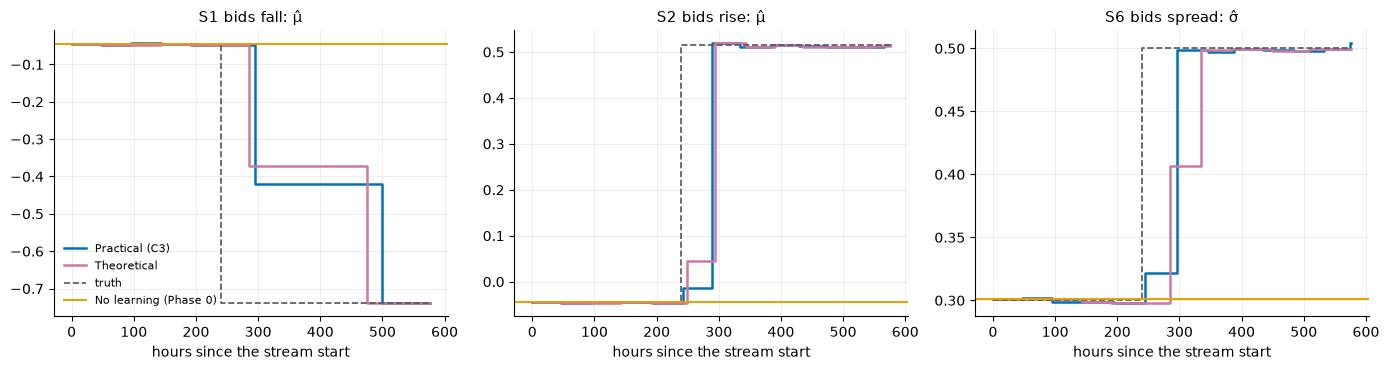

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (e, par) in zip(axes, (("s1_bids_fall", "mu"), ("s2_bids_rise", "mu"), ("s6_bids_spread", "sigma"))):
    for m in ("practical", "theoretical"):
        t = sa.markups(e, m)
        x = np.r_[t["start h"].to_numpy(), t["end h"].iloc[-1]]
        y = t[f"{par}_hat"].to_numpy()
        ax.step(x, np.r_[y, y[-1]], where="post", color=COLOR[m], lw=1.8, label=sa.LABEL[m])
    tr = sc.truth(sa.cfg(e))
    ax.step([0, T_STAR, x[-1]], [tr[f"{par}0"], tr[f"{par}1"], tr[f"{par}1"]], where="post", color="#555555",
            lw=1.2, ls="--", label="truth")
    ax.axhline(sa.markups(e, "practical")[f"{par}_hat"].iloc[0], color=COLOR["no_learning"], lw=1.4,
               label="No learning (Phase 0)")
    ax.set_title(f"{sa.ENV_LABEL[e]}: {'μ̂' if par == 'mu' else 'σ̂'}", fontsize=11)
    ax.set_xlabel("hours since the stream start")
    ax.grid(alpha=0.25, lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()

In [7]:
for e in ("s1_bids_fall", "s6_bids_spread", "s2_bids_rise"):
    print(sa.ENV_LABEL[e])
    display(sa.markups(e, "practical")[["phase", "start h", "end h", "end", "mu_hat", "sigma_hat", "tau CPU",  # noqa: F821
                                        "tau RAM", "true mu", "true sigma"]])

S1 bids fall


,phase,start h,end h,end,mu_hat,sigma_hat,tau CPU,tau RAM,true mu,true sigma
0,1,0.00,46.73,test1,-0.04,0.30,0.00,0.00,-0.04,0.30
1,2,46.73,95.65,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
2,3,95.65,143.08,test1,-0.04,0.30,0.00,0.00,-0.04,0.30
3,4,143.08,193.92,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
4,5,193.92,295.58,timeout,-0.05,0.30,0.00,0.00,-0.04,0.30
5,6,295.58,498.91,timeout,-0.42,0.46,0.00,0.00,-0.74,0.30
6,7,498.91,546.39,test1,-0.74,0.30,0.00,0.00,-0.74,0.30
7,8,546.39,575.90,horizon,-0.74,0.30,0.00,0.00,-0.74,0.30


S6 bids spread


,phase,start h,end h,end,mu_hat,sigma_hat,tau CPU,tau RAM,true mu,true sigma
0,1,0.00,46.73,test1,-0.04,0.30,0.00,0.00,-0.04,0.30
1,2,46.73,95.65,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
2,3,95.65,143.08,test1,-0.04,0.30,0.00,0.00,-0.04,0.30
3,4,143.08,193.92,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
4,5,193.92,243.90,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
5,6,243.90,296.06,test1,-0.05,0.32,0.00,0.00,-0.12,0.50
6,7,296.06,345.64,test1,-0.12,0.50,0.00,0.00,-0.12,0.50
7,8,345.64,386.99,test1,-0.13,0.50,0.00,0.00,-0.12,0.50
8,9,386.99,433.71,test1,-0.12,0.50,0.00,0.00,-0.12,0.50
9,10,433.71,484.24,test1,-0.13,0.50,0.00,0.00,-0.12,0.50


S2 bids rise


,phase,start h,end h,end,mu_hat,sigma_hat,tau CPU,tau RAM,true mu,true sigma
0,1,0.00,46.73,test1,-0.04,0.30,0.00,0.00,-0.04,0.30
1,2,46.73,95.65,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
2,3,95.65,143.08,test1,-0.04,0.30,0.00,0.00,-0.04,0.30
3,4,143.08,193.92,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
4,5,193.92,243.00,test1,-0.05,0.30,0.00,0.00,-0.04,0.30
5,6,243.00,288.44,test1,-0.01,0.32,0.00,0.00,0.51,0.30
6,7,288.44,334.84,test1,0.52,0.30,0.00,0.00,0.51,0.30
7,8,334.84,383.22,test1,0.51,0.30,0.00,0.00,0.51,0.30
8,9,383.22,429.69,test1,0.51,0.30,0.00,0.00,0.51,0.30
9,10,429.69,474.40,test1,0.51,0.30,0.00,0.00,0.51,0.30


## 4. Myerson check: expected against realised profit

For the admitted jobs, the profit φ·d − C_elec expected under the run's own markup model ("belief"), against the
realised profit, payment − C_elec. A stale model shows up as a ratio far from 1 after t*.

In [8]:
my = sa.myerson()
my.replace({"env": sa.ENV_LABEL, "model": sa.LABEL})[
    ["env", "model", "expected (belief) after", "realised after", "belief / realised after"]]

,env,model,expected (belief) after,realised after,belief / realised after
0,none (stationary),Greedy-Pos,"1,063.92","1,052.16",1.01
1,none (stationary),No learning,"1,123.65","1,121.83",1.00
2,none (stationary),Practical (C3),"1,130.93","1,126.71",1.00
3,none (stationary),Theoretical,858.98,855.94,1.00
4,S1 bids fall,Greedy-Pos,53.86,161.46,0.33
5,S1 bids fall,No learning,43.21,98.71,0.44
6,S1 bids fall,Practical (C3),198.34,280.51,0.71
7,S1 bids fall,Theoretical,167.14,251.62,0.66
8,S6 bids spread,Greedy-Pos,"1,202.67",968.46,1.24
9,S6 bids spread,No learning,"1,296.73","1,036.20",1.25


## 5. Bids in bin 1 (never admitted)

The grid is fixed at Phase 0. Halved bids below H's smallest bid fall into bin 1. This could be a limit of the
fixed grid. In practice it is small.

In [9]:
sa.bin1().replace({"env": sa.ENV_LABEL})

,env,bin 1 share before t*,bin 1 share after t*
0,none (stationary),0.00,0.00
1,S1 bids fall,0.00,0.01
2,S6 bids spread,0.00,0.00
3,S2 bids rise,0.00,0.00


## 6. Practical + calibrated tests

`tests.threshold: calibrated`: Test 2's threshold × κ2 = 0.00725 and Test 3's confidence terms × κ3 = 0.00427,
chosen on H with a safety factor of 2. There were 0 false alarms on the stationary stream
(`reports/week34/test_margins.md`, section 4). This section fills in once the four runs are cached.

In [10]:
if "practical_calibrated" in MODELS:
    d = sa.detection()
    display(d[d.model.isin(["practical", "practical_calibrated"])].replace(  # noqa: F821
        {"env": sa.ENV_LABEL, "model": sa.LABEL}))
    display(rw[rw.model.isin(["practical", "practical_calibrated", "no_learning"])].replace(  # noqa: F821
        {"env": sa.ENV_LABEL, "model": sa.LABEL})[["env", "model", "after t*", "% OPT after"]])
else:
    print("practical_calibrated is not cached in every environment yet")

practical_calibrated is not cached in every environment yet


## 7. The stationary runs against week 33

Week 34 estimates μ̂ (week 33 assumed μ = −σ²/2). On the stationary stream the totals move by about ±0.3%.

In [11]:
sa.week33_stationary()

,model,week 33,week 34,change %
0,practical,"3,094.73","3,104.05",0.30
1,theoretical,"2,256.17","2,248.04",-0.36
